# Nuclear health QC

Panel: raw DAPI | DAPI + nucleus outlines (colored by health flag) | pixel-intensity histogram within segmented nuclei.  
Channels: 405 nm DAPI, 488 nm MAP2, 561 nm TMEM106B (cleaved), 640 nm LAMP1. No mCherry.  
Rows: 3 days × 2 wells (C20, F20).

In [1]:
import os, sys
from pathlib import Path

# Locate worktree root by searching upward for pyproject.toml
_root = Path(os.getcwd()).resolve()
while not (_root / "pyproject.toml").exists():
    if _root == _root.parent:
        raise RuntimeError(f"Could not find repo root from {Path(os.getcwd()).resolve()}")
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
print(f"Repo root: {_root}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import Image, display
from skimage.segmentation import find_boundaries
from skimage.morphology import dilation, disk

from tmem_align.analysis.if_spatial import (
    CH_DAPI, apply_display_lut, load_fov, load_fov_3d, segment_nuclei,
)
from tmem_align.analysis.nuclear_health import apply_health_filter, nuclear_health_stats

REPORT_DIR = Path(os.getcwd()).resolve()
print(f"Output dir: {REPORT_DIR}")

Repo root: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg


Output dir: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc


In [2]:
# --- thresholds (tune after first run) ---
MIN_MEAN_INTENSITY = 300.0
MAX_SKEWNESS       = 2.0
MIN_NUCLEUS_AREA   = 50    # px — debris floor. Raised back from 20: at 20 the tiny per-slice
                           #   junk dominated. 50 drops the smallest blebs (accepted tradeoff);
                           #   50-200px pyknotic/necrotic nuclei still kept + flagged "skewed".
NECROTIC_AREA_MAX  = 200   # px — nuclei below this are pyknotic/necrotic → "skewed"
NUCLEUS_DIAMETER   = 25    # px. Re-tuned 2026-09-08: None (auto) under-detects small nuclei on
FLOW_THRESHOLD     = 0.4   # Cellpose default. NOTE: 0.8 + auto-diameter floods the background.
CELLPROB_THRESHOLD = 0.0   # detection floor. Lowered +1->0: the min_foreground_frac background-
                           #   contrast filter now handles precision, so cellprob can recover more.
BOUNDARY_DILATION  = 2     # px radius to thicken nucleus outlines for visibility
GPU                = True

# Which nuclei the segmentation hands downstream:
#   "healthy_only" — keep only viable nuclei; dead/dying dropped.
#   "all"          — keep every detected nucleus; dead/dying stay labeled and flagged,
#                    so downstream can attribute other-channel signal in that region to a
#                    dead/dying cell and exclude it, instead of mistaking it for a healthy cell.
SEGMENTATION_MODE = "all"

# Saturated colors that pop against a grayscale DAPI image (CVD-safe: green/cyan/orange)
HEALTH_COLORS = {"healthy": "#22CC55", "low_signal": "#33BBEE", "skewed": "#EE7722"}

DATA = Path("/Users/pmihack/claire/tmem_2026/data/cleaved_tmem_pld3_260821")
SUB  = "Z60_PLD_TMEMki"
PFX  = "PLD3TMEM106B_Plate1"
SFX  = "TMEM561LAMP1640MAP2488DAPI405"

FOVS = [
    {"day": "d7",  "well": "C20", "nd2": DATA / f"d7/{SUB}/{PFX}_d7_{SFX}_C20_F1.nd2"},
    {"day": "d7",  "well": "F20", "nd2": DATA / f"d7/{SUB}/{PFX}_d7_{SFX}_F20_F1.nd2"},
    {"day": "d14", "well": "C20", "nd2": DATA / f"d14/{SUB}/{PFX}_d14_{SFX}_C20_F1.nd2"},
    {"day": "d14", "well": "F20", "nd2": DATA / f"d14/{SUB}/{PFX}_d14_{SFX}_F20_F1.nd2"},
    {"day": "d28", "well": "C20", "nd2": DATA / f"d28/{SUB}/{PFX}_d28_{SFX}_C20_F1.nd2"},
    {"day": "d28", "well": "F20", "nd2": DATA / f"d28/{SUB}/{PFX}_d28_{SFX}_F20_F1.nd2"},
]

In [3]:
# Load, segment, compute stats for all FOVs
# `masks` = every detected nucleus (used by the QC panel below, colored by flag).
# `masks_out` = the handoff mask under SEGMENTATION_MODE — what downstream receives.
results = []
for fov in FOVS:
    print(f"Loading {fov['day']} well {fov['well']} ...")
    channels = load_fov(fov["nd2"])
    dapi     = channels[CH_DAPI]
    masks    = segment_nuclei(
        dapi, gpu=GPU,
        diameter=NUCLEUS_DIAMETER,
        flow_threshold=FLOW_THRESHOLD,
        cellprob_threshold=CELLPROB_THRESHOLD,
    )
    stats    = nuclear_health_stats(
        masks, dapi,
        min_mean_intensity=MIN_MEAN_INTENSITY,
        max_skewness=MAX_SKEWNESS,
        min_nucleus_area=MIN_NUCLEUS_AREA,
        necrotic_area_max=NECROTIC_AREA_MAX,
    )
    masks_out = apply_health_filter(masks, stats, mode=SEGMENTATION_MODE)
    results.append({**fov, "channels": channels, "masks": masks,
                    "masks_out": masks_out, "stats": stats})
    n = len(stats)
    nh = int(stats["is_healthy"].sum())
    n_handoff = int(np.unique(masks_out).size - 1)  # minus background label 0
    print(f"  {nh}/{n} healthy ({100*nh/max(n,1):.0f}%) — handoff ({SEGMENTATION_MODE}): {n_handoff} nuclei")

print("\nDone.")

Loading d7 well C20 ...


/Users/pmihack/claire/tmem_2026/tmem-neuron-aligner/.venv/lib/python3.13/site-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:823.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


  51/51 healthy (100%) — handoff (all): 51 nuclei
Loading d7 well F20 ...


  29/30 healthy (97%) — handoff (all): 30 nuclei
Loading d14 well C20 ...


  16/18 healthy (89%) — handoff (all): 18 nuclei
Loading d14 well F20 ...


  14/14 healthy (100%) — handoff (all): 14 nuclei
Loading d28 well C20 ...


  37/53 healthy (70%) — handoff (all): 53 nuclei
Loading d28 well F20 ...


  24/36 healthy (67%) — handoff (all): 36 nuclei

Done.


Saved: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc/dapi_panel_days_conditions.png


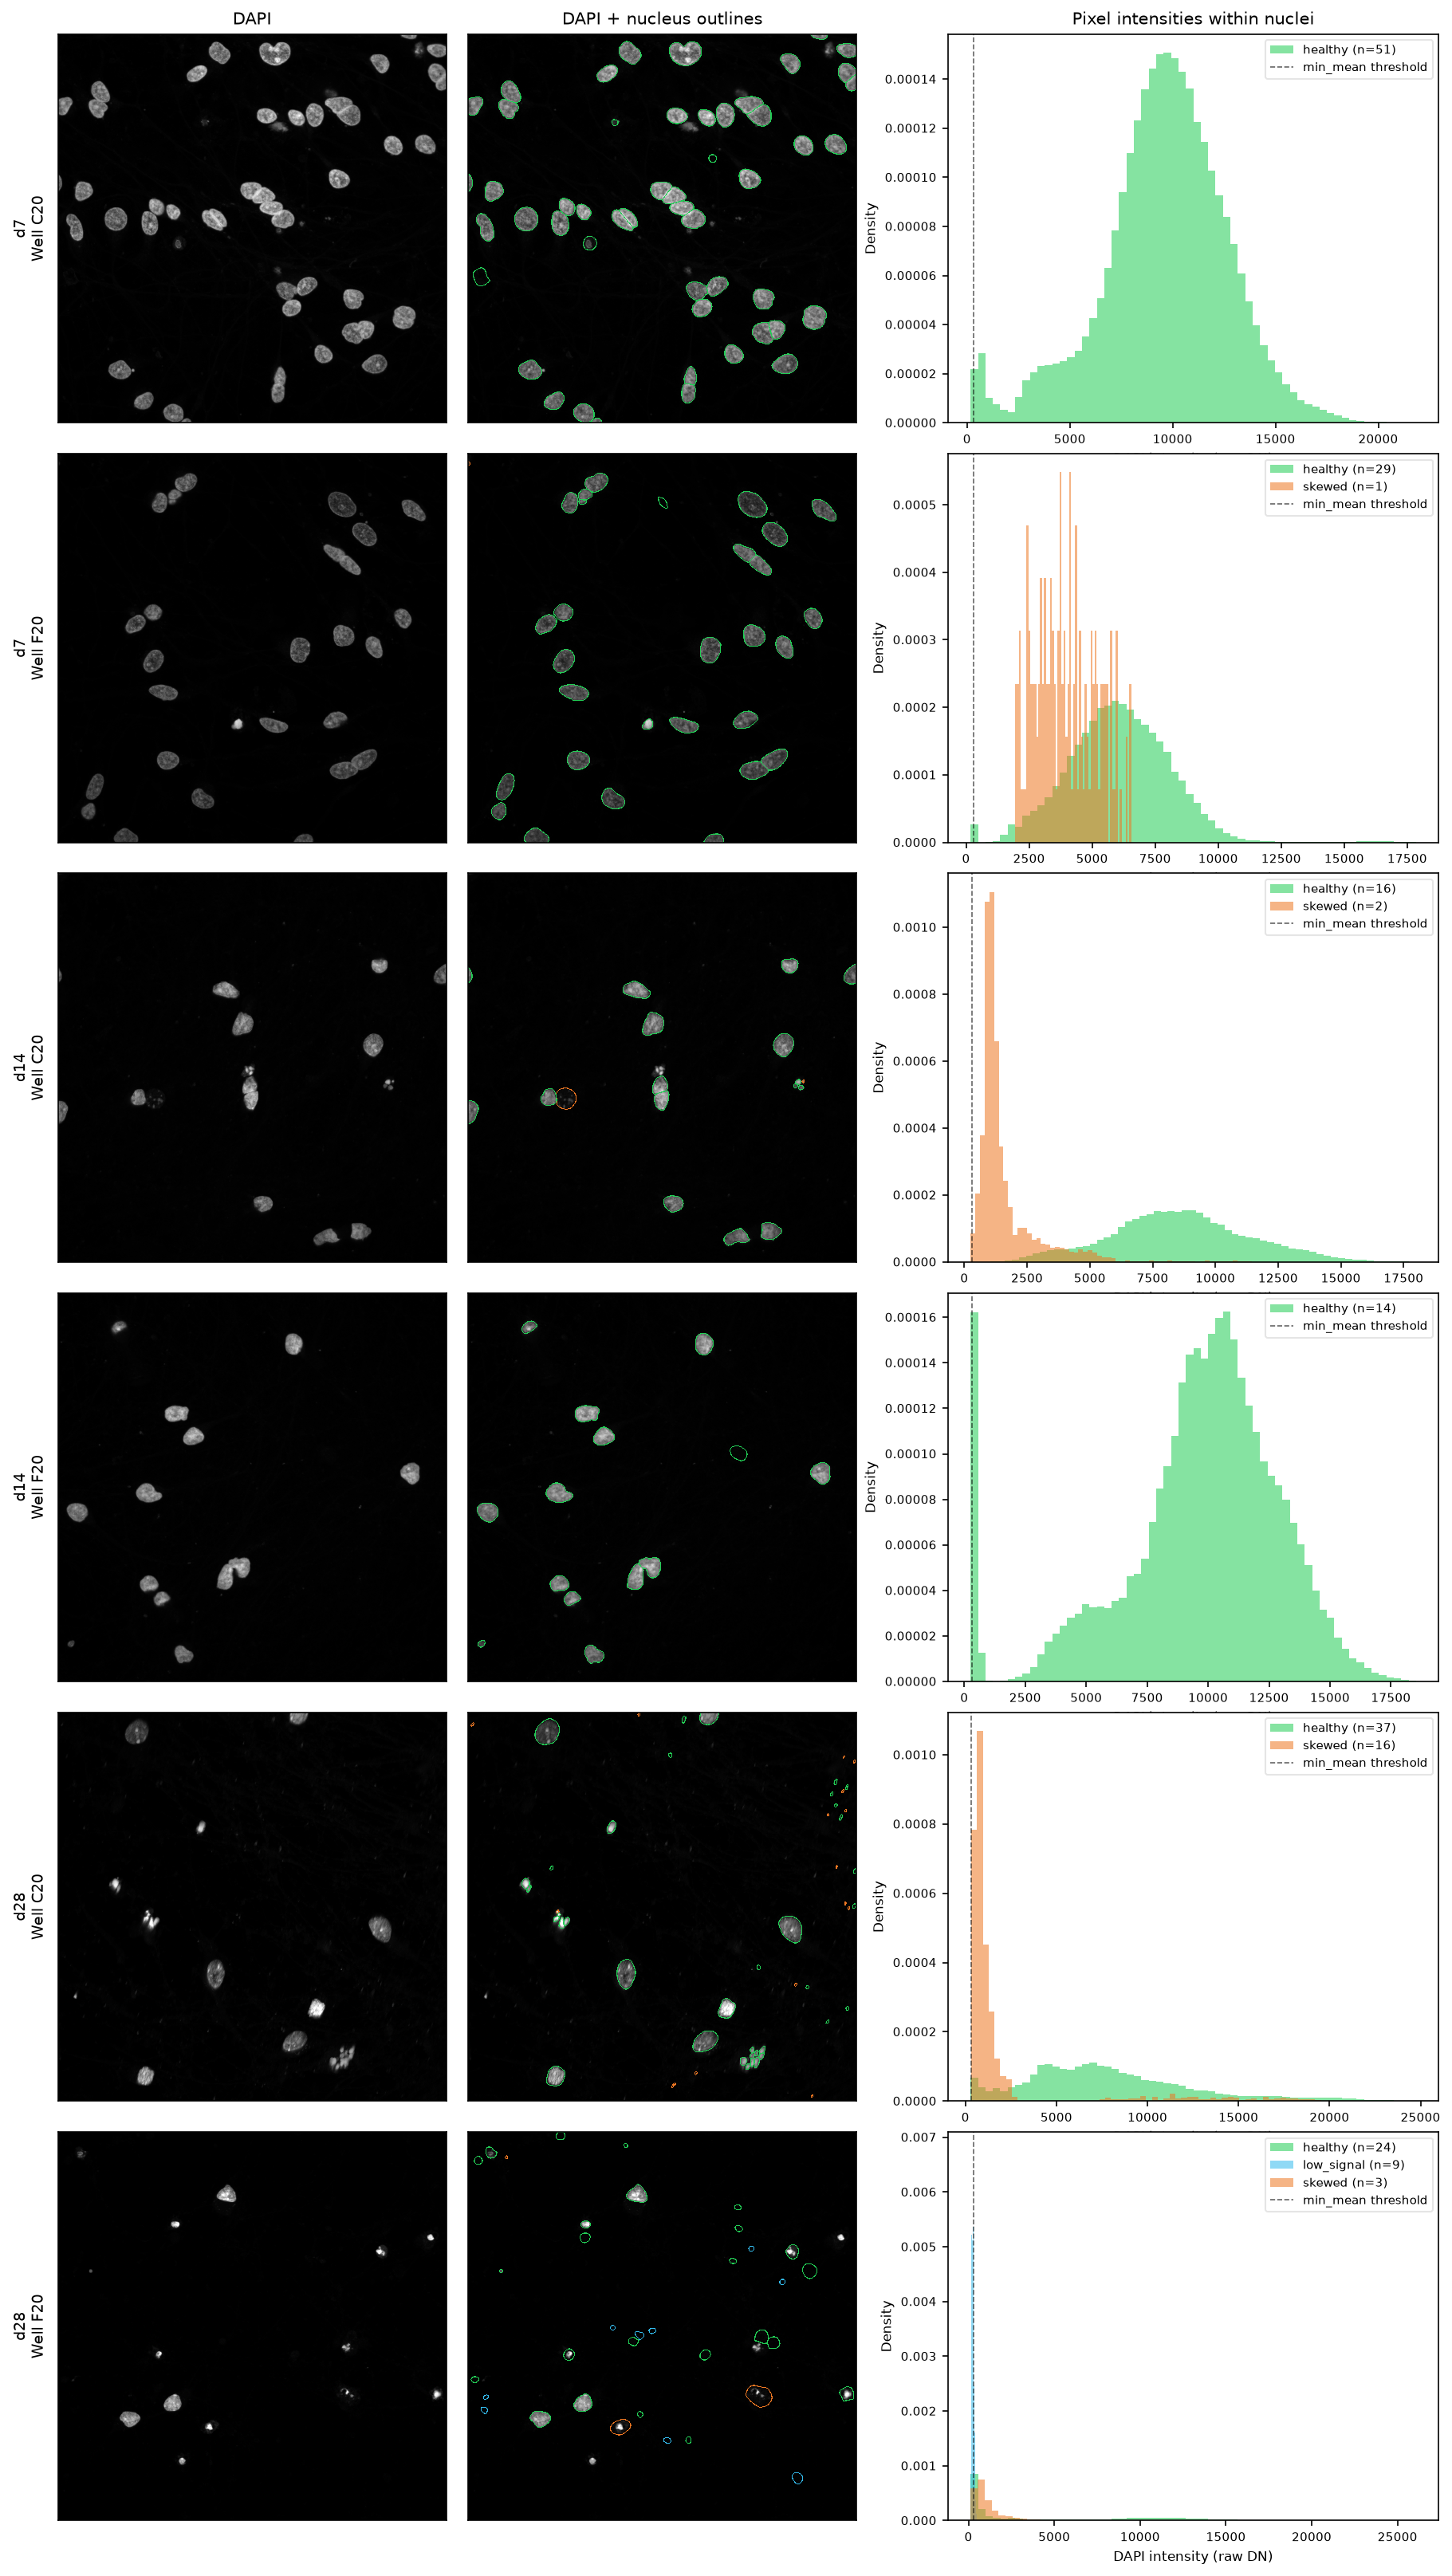

In [4]:
from matplotlib.gridspec import GridSpec

# Panel: rows = FOVs, cols = [raw DAPI | DAPI + nucleus outlines | pixel histogram]
# width_ratios cols 1 and 3 are spacers — col 1 tight, col 3 a bit wider
n_fovs = len(results)
fig = plt.figure(figsize=(15, 4.5 * n_fovs))
gs = GridSpec(n_fovs, 5, figure=fig,
              width_ratios=[1, 0.005, 1, 0.2, 1.2],
              hspace=0.08, wspace=0)

_disk = disk(BOUNDARY_DILATION)

for row, r in enumerate(results):
    dapi      = r["channels"][CH_DAPI]
    masks     = r["masks"]
    stats     = r["stats"]
    disp      = apply_display_lut(dapi, CH_DAPI)
    row_label = f"{r['day']}\nWell {r['well']}"

    ax_raw  = fig.add_subplot(gs[row, 0])
    ax_mask = fig.add_subplot(gs[row, 2])
    ax_hist = fig.add_subplot(gs[row, 4])

    # col 0: raw DAPI
    ax_raw.imshow(disp, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax_raw.set_ylabel(row_label, fontsize=9, labelpad=6)
    ax_raw.set_xticks([]); ax_raw.set_yticks([])
    if row == 0:
        ax_raw.set_title("DAPI", fontsize=10)

    # col 1: DAPI + nucleus outlines colored by health flag
    ax_mask.imshow(disp, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    overlay = np.zeros((*dapi.shape, 4), dtype=np.float32)
    for _, srow in stats.iterrows():
        lbl  = srow["nucleus_label"]
        flag = srow["health_flag"]
        bnd = dilation(find_boundaries(masks == lbl, mode="inner"), _disk)
        rgb = mcolors.to_rgb(HEALTH_COLORS[flag])
        overlay[bnd, :3] = rgb
        overlay[bnd, 3]  = 1.0
    ax_mask.imshow(overlay, interpolation="nearest")
    ax_mask.set_xticks([]); ax_mask.set_yticks([])
    if row == 0:
        ax_mask.set_title("DAPI + nucleus outlines", fontsize=10)

    # col 2: pixel intensity histogram within segmented nuclei
    for flag in ["healthy", "low_signal", "skewed"]:
        lbls = stats.loc[stats["health_flag"] == flag, "nucleus_label"].values
        if len(lbls) == 0:
            continue
        pixels = np.concatenate([dapi[masks == lbl].astype(np.float32) for lbl in lbls])
        ax_hist.hist(pixels, bins=60, alpha=0.55, color=HEALTH_COLORS[flag],
                     label=f"{flag} (n={len(lbls)})", density=True)
    ax_hist.axvline(MIN_MEAN_INTENSITY, color="black", lw=0.8, ls="--", alpha=0.6,
                    label="min_mean threshold")
    ax_hist.set_xlabel("DAPI intensity (raw DN)", fontsize=8)
    ax_hist.set_ylabel("Density", fontsize=8)
    ax_hist.tick_params(labelsize=7)
    ax_hist.legend(fontsize=7, framealpha=0.5)
    if row == 0:
        ax_hist.set_title("Pixel intensities within nuclei", fontsize=10)

png_path = REPORT_DIR / "dapi_panel_days_conditions.png"
fig.savefig(png_path, dpi=150, bbox_inches="tight")
plt.close(fig)
print(f"Saved: {png_path}")
display(Image(str(png_path)))

## Z-slice montage

Raw DAPI z-slices for a single FOV, with the max-projection nuclear mask overlaid on the bottom row.  
Set `FOV_IDX` to pick which FOV from the list above, and `N_SLICES` to control how many z-levels to show.

Loading 3D stack: d7 well C20 ...
  12 z-slices, voxel (z,y,x) µm: (0.3, 0.108, 0.108)


  Saved: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc/d7_C20_zslices.png


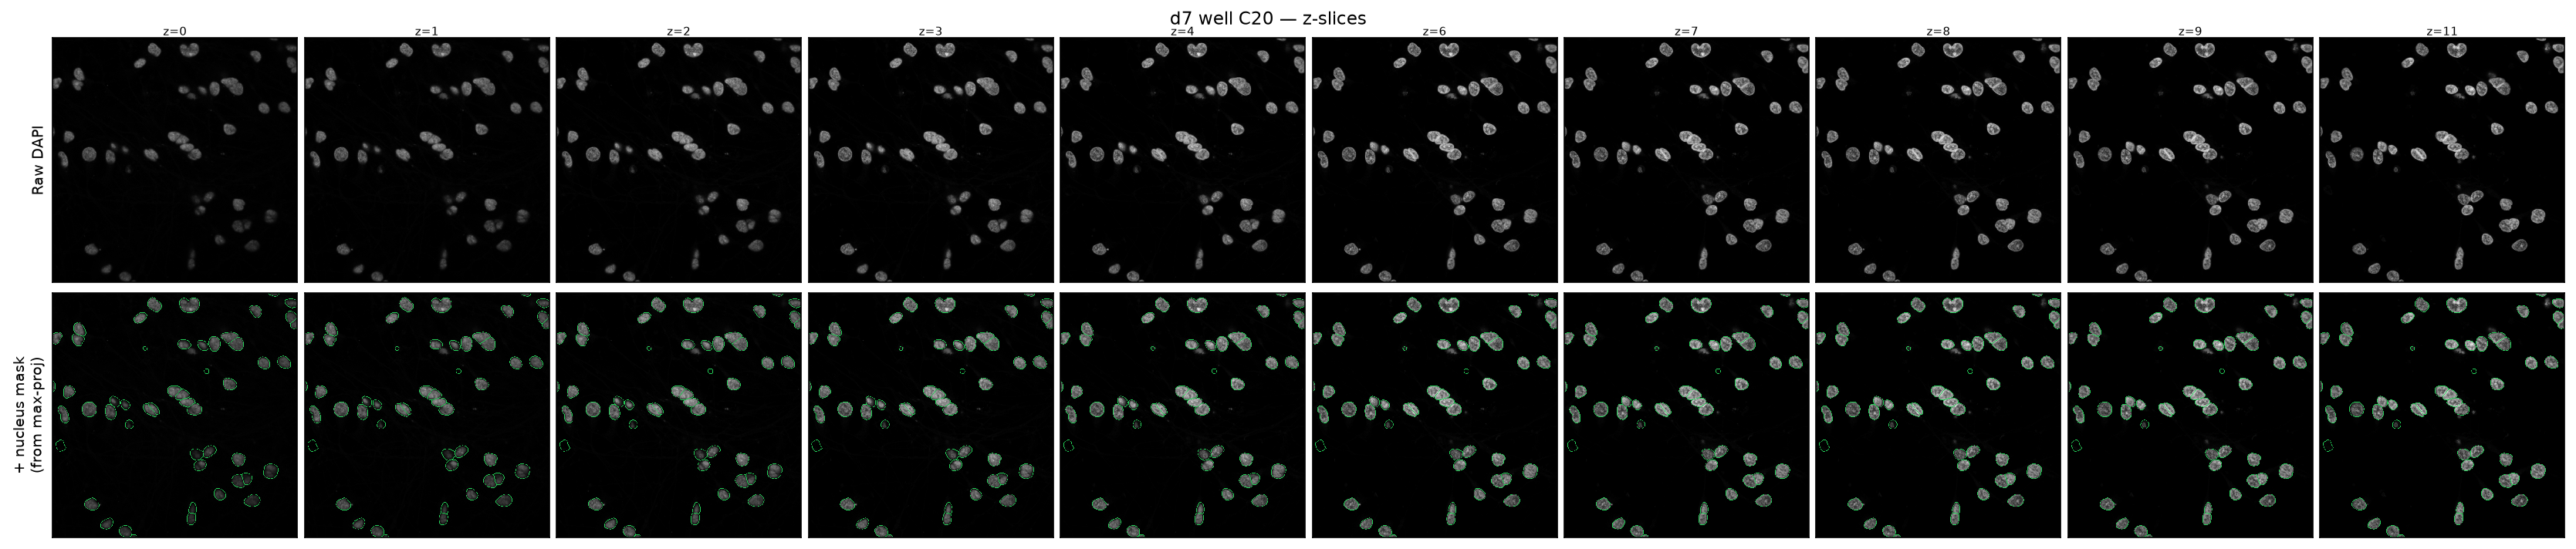

Loading 3D stack: d7 well F20 ...
  10 z-slices, voxel (z,y,x) µm: (0.3, 0.108, 0.108)


  Saved: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc/d7_F20_zslices.png


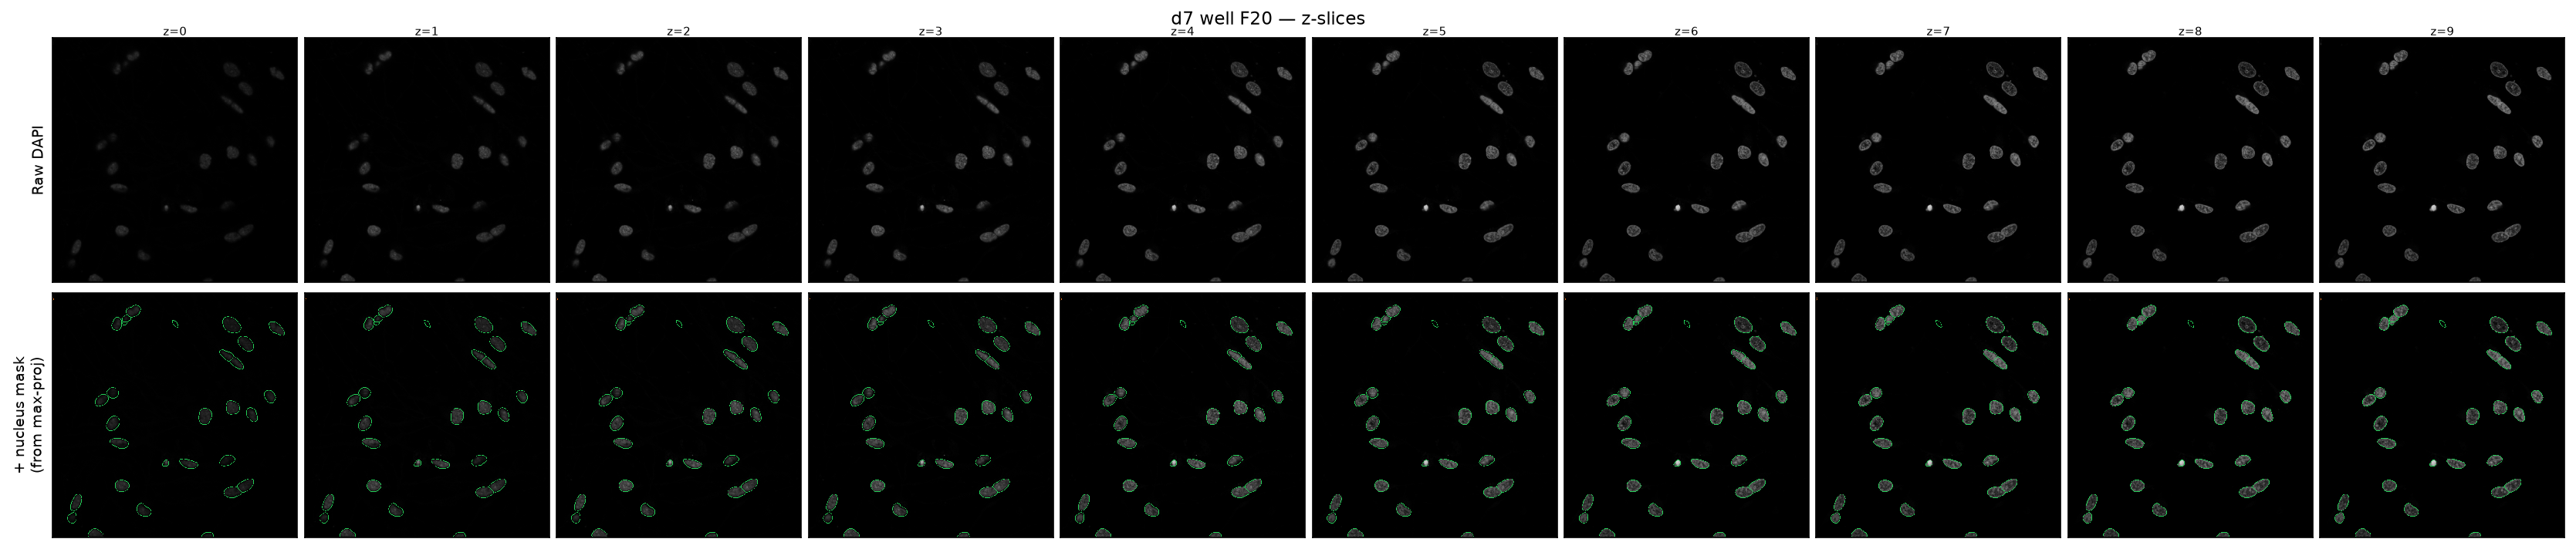

Loading 3D stack: d14 well C20 ...
  13 z-slices, voxel (z,y,x) µm: (0.3, 0.108, 0.108)


  Saved: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc/d14_C20_zslices.png


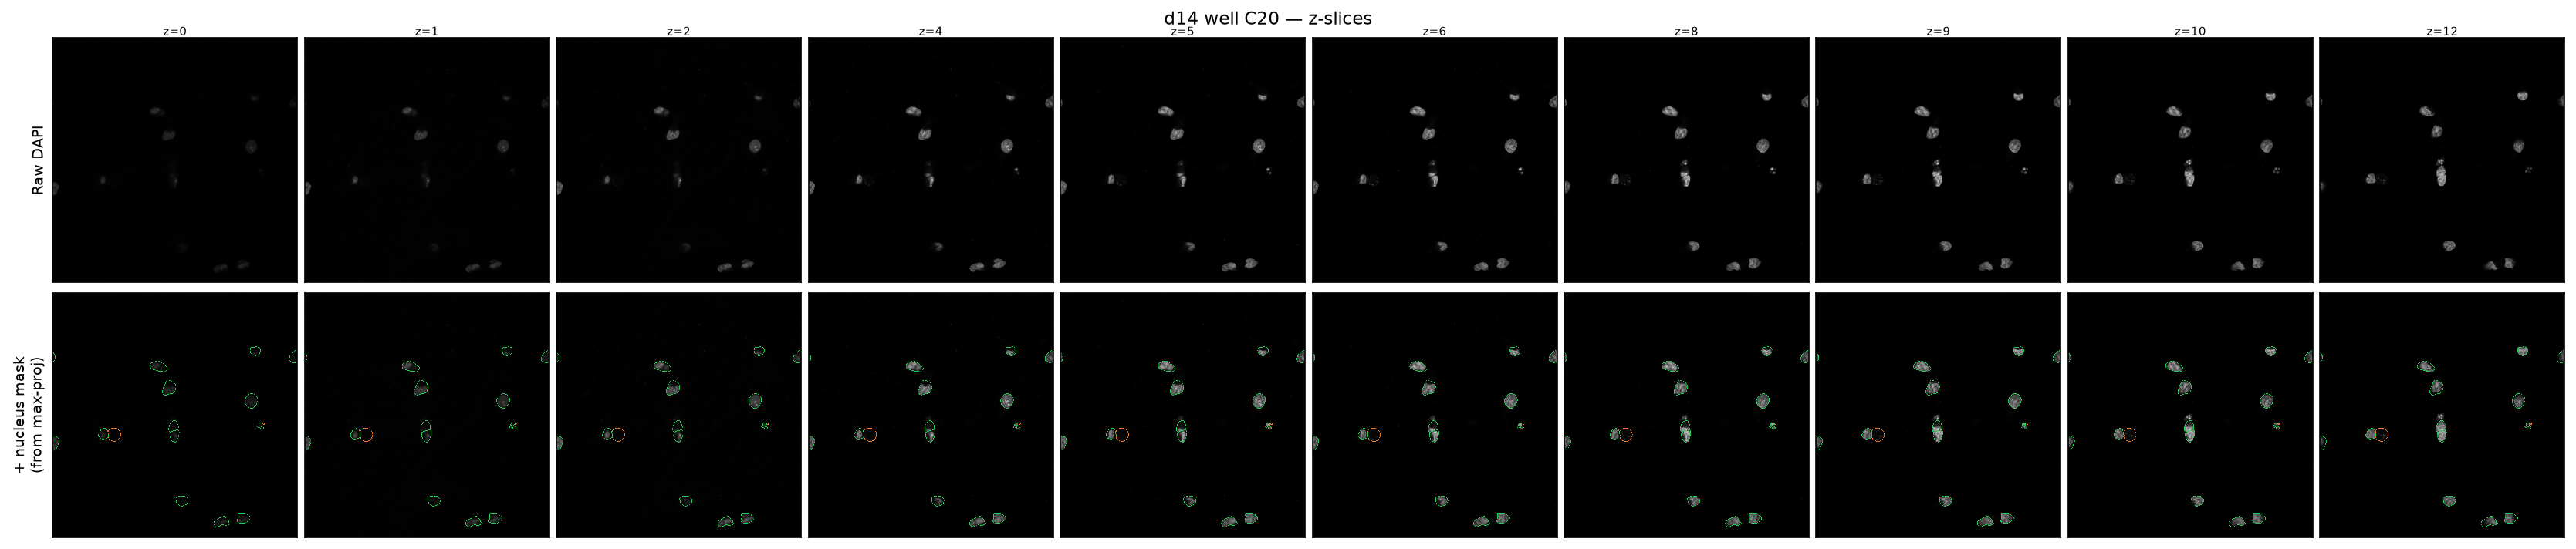

Loading 3D stack: d14 well F20 ...
  13 z-slices, voxel (z,y,x) µm: (0.3, 0.108, 0.108)


  Saved: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc/d14_F20_zslices.png


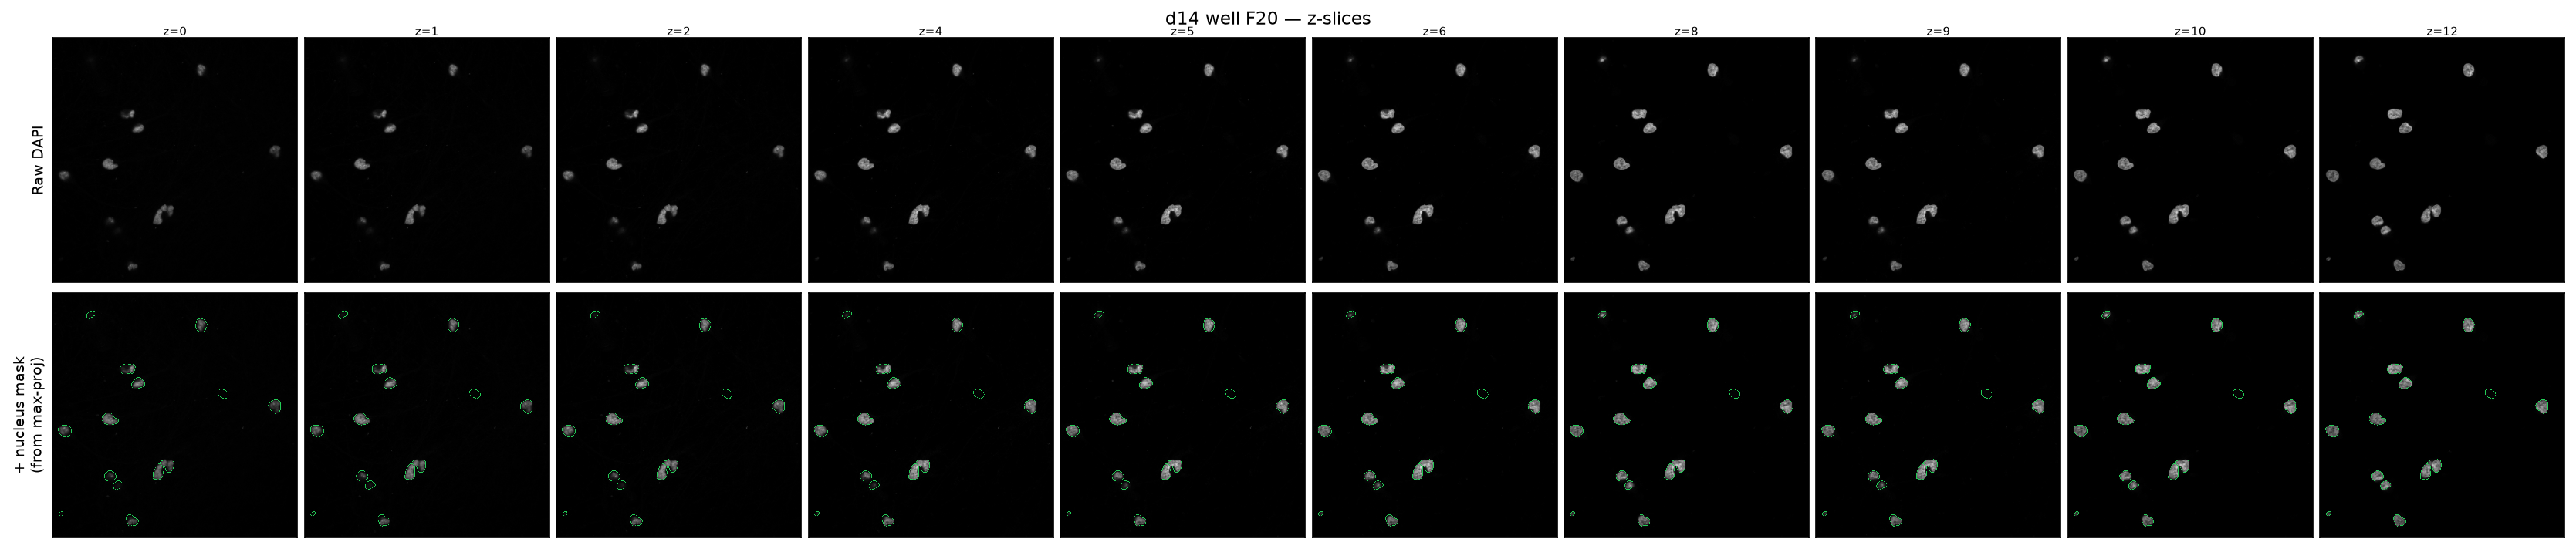

Loading 3D stack: d28 well C20 ...
  16 z-slices, voxel (z,y,x) µm: (0.3, 0.108, 0.108)


  Saved: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc/d28_C20_zslices.png


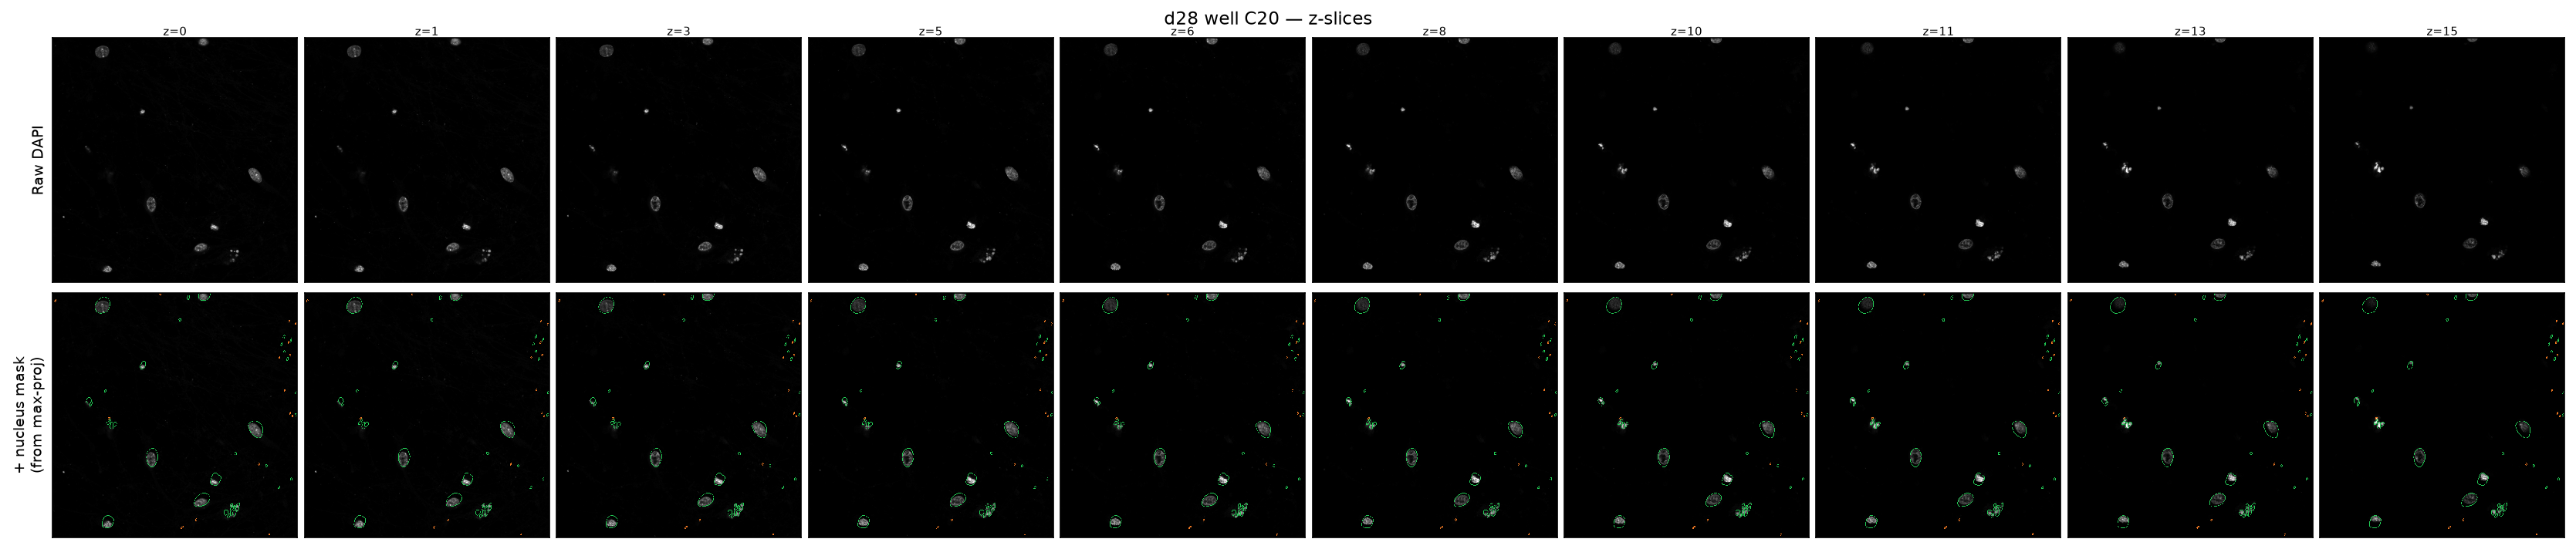

Loading 3D stack: d28 well F20 ...
  15 z-slices, voxel (z,y,x) µm: (0.3, 0.108, 0.108)


  Saved: /Users/pmihack/claire/tmem_2026/tmem-nuc-seg/reports/nuclear_health_qc/d28_F20_zslices.png


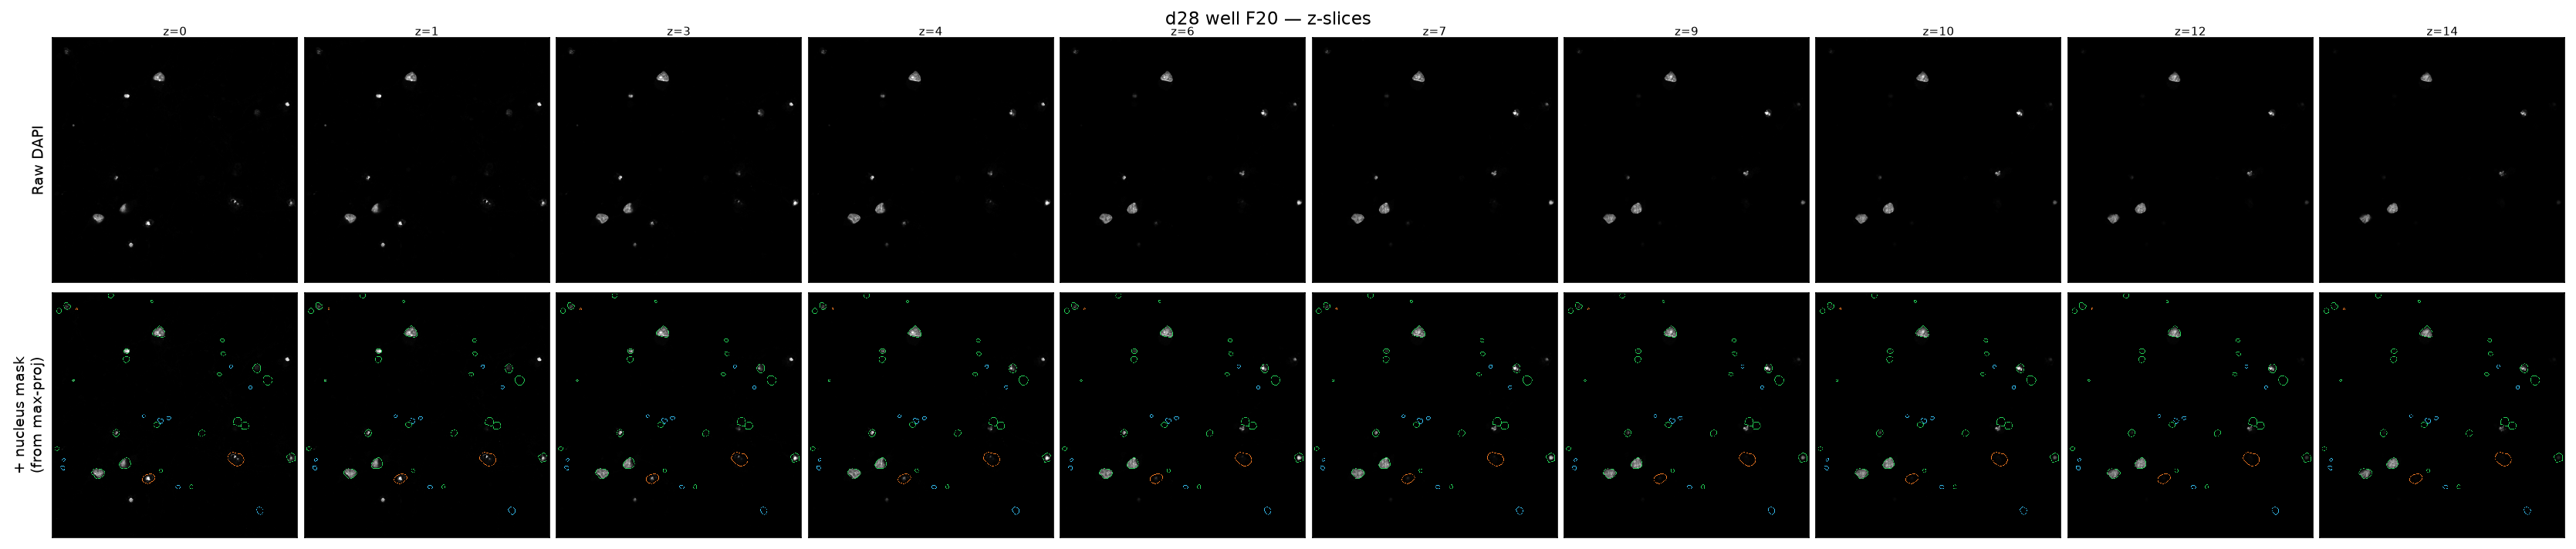

In [5]:
N_SLICES = 10  # evenly-spaced z-levels to display per FOV

_disk_z = disk(BOUNDARY_DILATION)

for i, r in enumerate(results):
    fov_meta = FOVS[i]
    print(f"Loading 3D stack: {fov_meta['day']} well {fov_meta['well']} ...")
    channels_3d, voxel_um = load_fov_3d(fov_meta["nd2"])
    dapi_3d  = channels_3d[CH_DAPI]
    n_z      = dapi_3d.shape[0]
    masks_2d = r["masks"]
    stats    = r["stats"]
    print(f"  {n_z} z-slices, voxel (z,y,x) µm: {tuple(round(v, 3) for v in voxel_um)}")

    overlay = np.zeros((*masks_2d.shape, 4), dtype=np.float32)
    for _, srow in stats.iterrows():
        lbl  = srow["nucleus_label"]
        flag = srow["health_flag"]
        bnd  = dilation(find_boundaries(masks_2d == lbl, mode="inner"), _disk_z)
        rgb  = mcolors.to_rgb(HEALTH_COLORS[flag])
        overlay[bnd, :3] = rgb
        overlay[bnd, 3]  = 1.0

    z_indices = np.linspace(0, n_z - 1, N_SLICES, dtype=int)

    fig, axes = plt.subplots(2, N_SLICES, figsize=(2.8 * N_SLICES, 5.2))
    fig.subplots_adjust(hspace=0.02, wspace=0.03, top=0.95)
    fig.suptitle(f"{fov_meta['day']} well {fov_meta['well']} — z-slices", fontsize=11, y=0.99)

    for col, z in enumerate(z_indices):
        disp = apply_display_lut(dapi_3d[z], CH_DAPI)

        axes[0, col].imshow(disp, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[0, col].set_title(f"z={z}", fontsize=7, pad=1)
        axes[0, col].set_xticks([]); axes[0, col].set_yticks([])

        axes[1, col].imshow(disp, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[1, col].imshow(overlay, interpolation="nearest")
        axes[1, col].set_xticks([]); axes[1, col].set_yticks([])

    axes[0, 0].set_ylabel("Raw DAPI", fontsize=9)
    axes[1, 0].set_ylabel("+ nucleus mask\n(from max-proj)", fontsize=9)

    png_z = REPORT_DIR / f"{fov_meta['day']}_{fov_meta['well']}_zslices.png"
    fig.savefig(png_z, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"  Saved: {png_z}")
    display(Image(str(png_z)))

In [6]:
# Summary: fraction healthy per day × well
summary = []
for r in results:
    s = r["stats"]
    n = len(s)
    summary.append({"day": r["day"], "well": r["well"],
                    "n_total": n, "n_healthy": int(s["is_healthy"].sum()),
                    "pct_healthy": round(100 * s["is_healthy"].mean(), 1)})
pd.DataFrame(summary)

,day,well,n_total,n_healthy,pct_healthy
0,d7,C20,51,51,100.0
1,d7,F20,30,29,96.7
2,d14,C20,18,16,88.9
3,d14,F20,14,14,100.0
4,d28,C20,53,37,69.8
5,d28,F20,36,24,66.7


## Segmentation handoff: the two options

`apply_health_filter(masks, stats, mode=...)` produces the label mask handed downstream.
- **`healthy_only`** — only viable nuclei; dead/dying dropped.
- **`all`** — every detected nucleus kept and flagged; dead/dying regions stay labeled so downstream can attribute other-channel signal to a dead/dying cell (and exclude it from biological quantification) rather than mistaking it for a healthy cell.

Active mode is set by `SEGMENTATION_MODE` above. The table compares label counts under each.

In [7]:
# Compare the two segmentation options per FOV (label counts of the handoff mask)
def _n_labels(m):
    return int(np.unique(m).size - 1)  # minus background label 0

handoff = []
for r in results:
    healthy_only = apply_health_filter(r["masks"], r["stats"], mode="healthy_only")
    all_nuclei   = apply_health_filter(r["masks"], r["stats"], mode="all")
    handoff.append({"day": r["day"], "well": r["well"],
                    "healthy_only": _n_labels(healthy_only),
                    "all": _n_labels(all_nuclei),
                    "dead_or_dying": _n_labels(all_nuclei) - _n_labels(healthy_only)})
print(f"Active SEGMENTATION_MODE = {SEGMENTATION_MODE!r}")
pd.DataFrame(handoff)

Active SEGMENTATION_MODE = 'all'


,day,well,healthy_only,all,dead_or_dying
0,d7,C20,51,51,0
1,d7,F20,29,30,1
2,d14,C20,16,18,2
3,d14,F20,14,14,0
4,d28,C20,37,53,16
5,d28,F20,24,36,12
